In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [34]:
class value:
    def __init__(self,data,_children=(), _op='',label=''):
        self.data=data
        self._prev=set(_children)
        self._op=_op
        self.grad=0.0
        self.label=label
    def __repr__(self):
        return f"value(Data = {self.data})"
    def __add__(self, other):
        result = value(self.data + other.data, (self, other), "+")
        return result
    def __mul__(self, other):
            result = value(self.data * other.data , (self,other),"*")
            return result

a=value(2.0,label='a')
b=value(-3.0,label='b')
c=value(1.0,label='c')
e=a*b;e.label='e'
d=e+c
d.label='d'
f=value(-2.0, label='f')

L=d*f;L.label='L'
    

In [35]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) 

    nodes, edges=trace(root)
    
    for n in nodes:
        
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

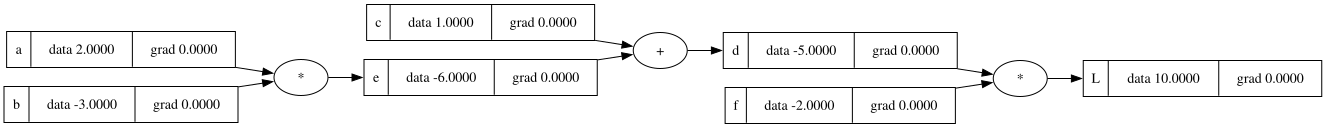

In [42]:
draw_dot(L)

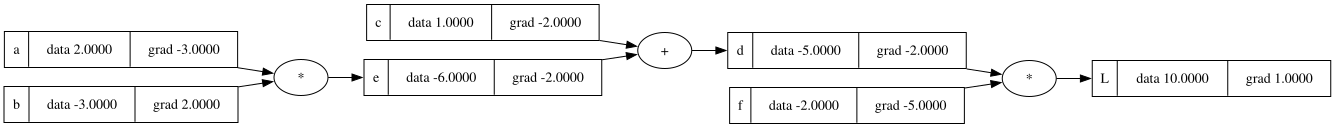

In [ ]:
# BackPropagation (gradient calculation)

L.grad=1.0
d.grad=-2.0 # L=d*f => dL/dd=f
f.grad=-5.0

c.grad=-2.0 # d=c+e => dL/dc=(dL/dd*dd/dc)=(f*1) {chain rule}
e.grad=-2.0 # d=c+e => dL/de=(dL/dd*dd/de)=(f*1)

a.grad=-3.0
b.grad=2.0

draw_dot(L)